# Infield Throw Performance Project - Modeling
**By:** Marchiano Oh (marchiano.oh@gmail.com)

**Notebook Contents:**
* [Evaluation Tool: Modeling](#Evaluation-Tool:-Modeling)
    * [Background](#Background)
    * [Feature Engineering](#Feature-Engineering)
        * [Missing Data Imputation](#Missing-Data-Imputation)
        * [Correlation Heatmap of Model Features](#Correlation-Heatmap-of-Model-Features)
    * [Model Development](#Model-Development)
    * [Linking Model Prediction to Throw Performance](#Linking-Model-Prediction-to-Throw-Performance)
    * [Future Directions](#Future-Directions)

## Evaluation Tool: Modeling

In [1]:
# Import necessary Python libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
from sklearn.impute import KNNImputer
from sklearn.metrics import f1_score
import pycaret.classification as pycaret

In [2]:
# Import the dataset
working_directory = 'C:\\Users\\Marchiano\\Documents\\Infield Throw Performance Project\\'

fielder_throws_df = pd.read_csv(working_directory + 'dataset_2026.csv', header=0)

# Show snippet of dataset to preview data and verify import was done 
fielder_throws_df.head()

,throw_id,team_id,fielder_id,fielder_position,thrower_id,thrower_position,receiver_id,receiver_position,exchange_time,throw_pos_x,...,bounce_velo_y,bounce_velo_z,receiver_pos_x,receiver_pos_y,receiver_dist_from_1b,throw_deflected_by_receiver,start_state,end_state,runs_on_play,batter_result
0,3,11,400,6,400,6,63,3,1.533,-60.116123,...,-25.452504,7.330194,56.199323,60.187776,8.202015,0,____1,1___1,0,first
1,6,11,228,5,390,4,63,3,0.534,-0.562563,...,NaN,NaN,59.013134,65.657938,5.047566,0,1___1,1___2,0,first
2,7,8,415,4,415,4,143,3,1.266,1.598751,...,NaN,NaN,61.037489,64.429134,2.719261,0,123_1,____3,0,out
3,8,8,308,1,308,1,143,3,1.800,25.403185,...,NaN,NaN,63.142075,65.648720,2.069797,0,____1,____2,0,out
4,10,1,314,4,300,6,514,3,0.733,8.957441,...,NaN,NaN,59.770395,64.046058,3.890504,0,123_1,____3,0,out


### Background
Since the goal of infielders within the context of the provided dataset is to throw out at first the batter who hit a ground ball, infielder talent will be evaluated on their ability to make a throw that retires the batter who put a ground ball in play.

Aspects of a good infield throw to first are:
* Quick exchange
* Fast throw without bounce(s) or deflection(s)
* Accuracy that makes the throw on target and prevents it from being errant

The outcome of an infield throw to first is out or safe. Thus, the prediction model is a classification machine learning model. The target feature for this modeling project will be a categorical `batter_out` feature that will have 0 to represent the batter being safe at first and 1 to represent the batter being thrown out.

Since the modeling focus is on throws by infielders, only rows from the original dataset that have a `throw_position` of 3, 4, 5, or 6 will be included in the modeling dataset.


In [10]:
# Retrieve only rows with throws made by infielders
modeling_throws_raw_df = fielder_throws_df.query("thrower_position in [3, 4, 5, 6]")
modeling_throws_raw_df

,throw_id,team_id,fielder_id,fielder_position,thrower_id,thrower_position,receiver_id,receiver_position,exchange_time,throw_pos_x,...,bounce_velo_y,bounce_velo_z,receiver_pos_x,receiver_pos_y,receiver_dist_from_1b,throw_deflected_by_receiver,start_state,end_state,runs_on_play,batter_result
0,3,11,400,6,400,6,63,3,1.533,-60.116123,...,-25.452504,7.330194,56.199323,60.187776,8.202015,0,____1,1___1,0,first
1,6,11,228,5,390,4,63,3,0.534,-0.562563,...,NaN,NaN,59.013134,65.657938,5.047566,0,1___1,1___2,0,first
2,7,8,415,4,415,4,143,3,1.266,1.598751,...,NaN,NaN,61.037489,64.429134,2.719261,0,123_1,____3,0,out
4,10,1,314,4,300,6,514,3,0.733,8.957441,...,NaN,NaN,59.770395,64.046058,3.890504,0,123_1,____3,0,out
5,11,2,312,4,312,4,695,3,1.200,15.075073,...,NaN,NaN,59.622860,63.940860,4.028031,0,____0,____1,0,out
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19994,33188,1,507,5,507,5,63,3,0.933,-21.462272,...,NaN,NaN,60.758995,63.767877,2.883469,0,1_3_2,____3,0,out
19995,33189,1,300,6,187,4,63,3,0.567,-0.706883,...,-32.706535,8.013511,61.579339,66.498556,3.523959,0,123_1,1_3_2,1,first
19997,33192,1,63,3,300,6,63,3,1.266,7.741671,...,NaN,NaN,59.986376,65.275522,4.002790,0,1___1,____3,0,out
19998,33193,15,713,4,713,4,313,3,1.200,65.300092,...,NaN,NaN,60.946962,64.565955,2.847538,0,____2,____3,0,out


`team_id`, `fielder_id`, `fielder_position` `thrower_id`, `thrower_position`, `receiver_id` are features that describe the context of a throw (i.e., who threw to first base, what position does the thrower play, what team does the thrower play for, who caught it, etc.). Therefore, they are included in the modeling data. These features also do not have any `NA` values.

In [11]:
# Check the number 'NA' values for each column in the infielder throw dataset
modeling_throws_raw_df.isna().sum()

throw_id                           0
team_id                            0
fielder_id                         0
fielder_position                   0
thrower_id                         0
thrower_position                   0
receiver_id                        0
receiver_position                  0
exchange_time                      6
throw_pos_x                       11
throw_pos_y                       11
throw_velo_x                      12
throw_velo_y                      12
throw_velo_z                      12
batter_pos_x_at_throw             25
batter_pos_y_at_throw             25
batter_velo_at_throw              25
bounce_pos_x                   15982
bounce_pos_y                   15982
bounce_velo_x                  15982
bounce_velo_y                  15982
bounce_velo_z                  15982
receiver_pos_x                    25
receiver_pos_y                    25
receiver_dist_from_1b             25
throw_deflected_by_receiver        0
start_state                        0
e

In [12]:
# Index original dataset for ID and position features
modeling_throws_feateng_df = modeling_throws_raw_df.loc[:, ['team_id', 'fielder_id', 'fielder_position', 'thrower_id', 'thrower_position', 'receiver_id']]
modeling_throws_feateng_df

,team_id,fielder_id,fielder_position,thrower_id,thrower_position,receiver_id
0,11,400,6,400,6,63
1,11,228,5,390,4,63
2,8,415,4,415,4,143
4,1,314,4,300,6,514
5,2,312,4,312,4,695
...,...,...,...,...,...,...
19994,1,507,5,507,5,63
19995,1,300,6,187,4,63
19997,1,63,3,300,6,63
19998,15,713,4,713,4,313


[Back to List of Notebook Contents](#Infield-Throw-Performance-Project---Modeling)

### Feature Engineering

The goal upon completing feature engineering is to have a clean dataframe only with features and their values that will be passed into modeling algorithms.

`exchange_time`, `throw_pos`, `throw_velo`, and `batter_pos` features have `NA` values, but are relevant when evaluate infielder talent. Thus, they will be added to the modeling data now and undergo imputation to replace the `NA` values later. 

In [13]:
# Add the features mentioned above without imputation for now to include them in the modeling data
modeling_throws_feateng_df = pd.concat([modeling_throws_feateng_df, modeling_throws_raw_df.loc[:,
    ['exchange_time', 'throw_pos_x', 'throw_pos_y', 'throw_velo_x', 'throw_velo_y', 'throw_velo_z', 'batter_pos_x_at_throw', 'batter_pos_y_at_throw', 'batter_velo_at_throw']]], axis=1)

modeling_throws_feateng_df

,team_id,fielder_id,fielder_position,thrower_id,thrower_position,receiver_id,exchange_time,throw_pos_x,throw_pos_y,throw_velo_x,throw_velo_y,throw_velo_z,batter_pos_x_at_throw,batter_pos_y_at_throw,batter_velo_at_throw
0,11,400,6,400,6,63,1.533,-60.116123,132.187283,60.047557,-33.596364,8.583470,26.912908,26.556102,25.787532
1,11,228,5,390,4,63,0.534,-0.562563,122.821943,51.293917,-45.316519,8.831870,43.396413,44.290491,28.647878
2,8,415,4,415,4,143,1.266,1.598751,123.036931,50.049649,-41.717447,5.986785,25.300783,29.970718,25.130428
4,1,314,4,300,6,514,0.733,8.957441,126.165878,51.630666,-63.361730,7.811719,40.118296,41.433396,27.318509
5,2,312,4,312,4,695,1.200,15.075073,138.722465,41.263285,-62.250650,6.230779,39.704962,41.805751,27.578044
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19994,1,507,5,507,5,63,0.933,-21.462272,54.318477,68.603145,10.954987,5.754307,37.129574,37.198314,28.284878
19995,1,300,6,187,4,63,0.567,-0.706883,127.257516,53.870710,-48.222079,0.569104,43.840928,45.840910,27.057959
19997,1,63,3,300,6,63,1.266,7.741671,124.743020,48.088435,-52.227491,8.389313,40.034865,42.092314,20.951101
19998,15,713,4,713,4,313,1.200,65.300092,140.347984,-3.137041,-69.775213,9.328455,34.015906,33.508358,19.628322


Exploratory data analysis showed that the fielder and thrower were different for some throws. This difference may alter the level of difficulty of the throw to be made. The throw can be easier to record an out if the ball travels fortuitously straight the thrower (e.g., soft initial feed on a 6-4-3 double play leading to a quicker exchange) or make it an off-balance throw and less likely to record an out on if the ball is unfavorably deflected.

A feature describing whether the fielder and thrower is the same is made.

In [16]:
# Make a feature that compares the fielder_position and thrower_position
# The output will be 1 if the fielder_position and thrower_position are the same and 0 if they are different
modeling_throws_feateng_df['fielder_thrower_same'] = (modeling_throws_raw_df['fielder_position'] == modeling_throws_raw_df['thrower_position']).astype(int).copy()
modeling_throws_feateng_df

,team_id,fielder_id,fielder_position,thrower_id,thrower_position,receiver_id,exchange_time,throw_pos_x,throw_pos_y,throw_velo_x,throw_velo_y,throw_velo_z,batter_pos_x_at_throw,batter_pos_y_at_throw,batter_velo_at_throw,fielder_thrower_same
0,11,400,6,400,6,63,1.533,-60.116123,132.187283,60.047557,-33.596364,8.583470,26.912908,26.556102,25.787532,1
1,11,228,5,390,4,63,0.534,-0.562563,122.821943,51.293917,-45.316519,8.831870,43.396413,44.290491,28.647878,0
2,8,415,4,415,4,143,1.266,1.598751,123.036931,50.049649,-41.717447,5.986785,25.300783,29.970718,25.130428,1
4,1,314,4,300,6,514,0.733,8.957441,126.165878,51.630666,-63.361730,7.811719,40.118296,41.433396,27.318509,0
5,2,312,4,312,4,695,1.200,15.075073,138.722465,41.263285,-62.250650,6.230779,39.704962,41.805751,27.578044,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19994,1,507,5,507,5,63,0.933,-21.462272,54.318477,68.603145,10.954987,5.754307,37.129574,37.198314,28.284878,1
19995,1,300,6,187,4,63,0.567,-0.706883,127.257516,53.870710,-48.222079,0.569104,43.840928,45.840910,27.057959,0
19997,1,63,3,300,6,63,1.266,7.741671,124.743020,48.088435,-52.227491,8.389313,40.034865,42.092314,20.951101,0
19998,15,713,4,713,4,313,1.200,65.300092,140.347984,-3.137041,-69.775213,9.328455,34.015906,33.508358,19.628322,1


To describe a clean throw (i.e., does not bounce while traveling to first), `bounce_pos` and `bounce_velo` features are used to determine if a bounce occurred on the throw.

In [19]:
# Create a feature that indicates whether a throw bounced, evidenced by the presence of non-'NA' values in the bounce features
# 0: no bounce occurred, 1: bounce occurred
modeling_throws_feateng_df['throw_bounced'] = (modeling_throws_raw_df['bounce_pos_x'].notna() &
                                                     modeling_throws_raw_df['bounce_pos_y'].notna() &
                                                     modeling_throws_raw_df['bounce_velo_x'].notna() &
                                                     modeling_throws_raw_df['bounce_velo_y'].notna() &
                                                     modeling_throws_raw_df['bounce_velo_z'].notna()).astype(int).copy()

modeling_throws_feateng_df

,team_id,fielder_id,fielder_position,thrower_id,thrower_position,receiver_id,exchange_time,throw_pos_x,throw_pos_y,throw_velo_x,throw_velo_y,throw_velo_z,batter_pos_x_at_throw,batter_pos_y_at_throw,batter_velo_at_throw,fielder_thrower_same,throw_bounced
0,11,400,6,400,6,63,1.533,-60.116123,132.187283,60.047557,-33.596364,8.583470,26.912908,26.556102,25.787532,1,1
1,11,228,5,390,4,63,0.534,-0.562563,122.821943,51.293917,-45.316519,8.831870,43.396413,44.290491,28.647878,0,0
2,8,415,4,415,4,143,1.266,1.598751,123.036931,50.049649,-41.717447,5.986785,25.300783,29.970718,25.130428,1,0
4,1,314,4,300,6,514,0.733,8.957441,126.165878,51.630666,-63.361730,7.811719,40.118296,41.433396,27.318509,0,0
5,2,312,4,312,4,695,1.200,15.075073,138.722465,41.263285,-62.250650,6.230779,39.704962,41.805751,27.578044,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19994,1,507,5,507,5,63,0.933,-21.462272,54.318477,68.603145,10.954987,5.754307,37.129574,37.198314,28.284878,1,0
19995,1,300,6,187,4,63,0.567,-0.706883,127.257516,53.870710,-48.222079,0.569104,43.840928,45.840910,27.057959,0,1
19997,1,63,3,300,6,63,1.266,7.741671,124.743020,48.088435,-52.227491,8.389313,40.034865,42.092314,20.951101,0,0
19998,15,713,4,713,4,313,1.200,65.300092,140.347984,-3.137041,-69.775213,9.328455,34.015906,33.508358,19.628322,1,0


To further describe a clean throw, the `throw_deflected_by_receiver` feature is added to the data that will be part of the model.

In [20]:
# Add throw_deflected_by_receiver feature to dataset
modeling_throws_feateng_df['throw_deflected_by_receiver'] = modeling_throws_raw_df['throw_deflected_by_receiver'].copy()
modeling_throws_feateng_df

,team_id,fielder_id,fielder_position,thrower_id,thrower_position,receiver_id,exchange_time,throw_pos_x,throw_pos_y,throw_velo_x,throw_velo_y,throw_velo_z,batter_pos_x_at_throw,batter_pos_y_at_throw,batter_velo_at_throw,fielder_thrower_same,throw_bounced,throw_deflected_by_receiver
0,11,400,6,400,6,63,1.533,-60.116123,132.187283,60.047557,-33.596364,8.583470,26.912908,26.556102,25.787532,1,1,0
1,11,228,5,390,4,63,0.534,-0.562563,122.821943,51.293917,-45.316519,8.831870,43.396413,44.290491,28.647878,0,0,0
2,8,415,4,415,4,143,1.266,1.598751,123.036931,50.049649,-41.717447,5.986785,25.300783,29.970718,25.130428,1,0,0
4,1,314,4,300,6,514,0.733,8.957441,126.165878,51.630666,-63.361730,7.811719,40.118296,41.433396,27.318509,0,0,0
5,2,312,4,312,4,695,1.200,15.075073,138.722465,41.263285,-62.250650,6.230779,39.704962,41.805751,27.578044,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19994,1,507,5,507,5,63,0.933,-21.462272,54.318477,68.603145,10.954987,5.754307,37.129574,37.198314,28.284878,1,0,0
19995,1,300,6,187,4,63,0.567,-0.706883,127.257516,53.870710,-48.222079,0.569104,43.840928,45.840910,27.057959,0,1,0
19997,1,63,3,300,6,63,1.266,7.741671,124.743020,48.088435,-52.227491,8.389313,40.034865,42.092314,20.951101,0,0,0
19998,15,713,4,713,4,313,1.200,65.300092,140.347984,-3.137041,-69.775213,9.328455,34.015906,33.508358,19.628322,1,0,0


To reflect a team's and infielder's ability to make a clean throw, the bounced throw rate is calculated using the formula
`number of throws bounced by team/player / total number of throws made by team/player`. The deflected throw rate in the same manner but considering the throws that were deflected.

In [21]:
# Create a bounced and deflected throw rate for each team and player

# Team rates
modeling_throws_feateng_df['team_bounced_throw_rate'] = (modeling_throws_feateng_df.groupby('team_id')['throw_bounced'].transform('sum') / modeling_throws_feateng_df.groupby('team_id')['throw_bounced'].transform('count')).copy()
modeling_throws_feateng_df['team_deflected_throw_rate'] = (modeling_throws_feateng_df.groupby('team_id')['throw_deflected_by_receiver'].transform('sum') / modeling_throws_feateng_df.groupby('team_id')['throw_deflected_by_receiver'].transform('count')).copy()

# Thrower rates
modeling_throws_feateng_df['thrower_bounced_throw_rate'] = (modeling_throws_feateng_df.groupby('thrower_id')['throw_bounced'].transform('sum') / modeling_throws_feateng_df.groupby('thrower_id')['throw_bounced'].transform('count')).copy()
modeling_throws_feateng_df['thrower_deflected_throw_rate'] = (modeling_throws_feateng_df.groupby('thrower_id')['throw_deflected_by_receiver'].transform('sum') / modeling_throws_feateng_df.groupby('thrower_id')['throw_deflected_by_receiver'].transform('count')).copy()

modeling_throws_feateng_df

,team_id,fielder_id,fielder_position,thrower_id,thrower_position,receiver_id,exchange_time,throw_pos_x,throw_pos_y,throw_velo_x,...,batter_pos_x_at_throw,batter_pos_y_at_throw,batter_velo_at_throw,fielder_thrower_same,throw_bounced,throw_deflected_by_receiver,team_bounced_throw_rate,team_deflected_throw_rate,thrower_bounced_throw_rate,thrower_deflected_throw_rate
0,11,400,6,400,6,63,1.533,-60.116123,132.187283,60.047557,...,26.912908,26.556102,25.787532,1,1,0,0.083045,0.019031,0.286822,0.015504
1,11,228,5,390,4,63,0.534,-0.562563,122.821943,51.293917,...,43.396413,44.290491,28.647878,0,0,0,0.083045,0.019031,0.022388,0.014925
2,8,415,4,415,4,143,1.266,1.598751,123.036931,50.049649,...,25.300783,29.970718,25.130428,1,0,0,0.078631,0.024977,0.055556,0.025641
4,1,314,4,300,6,514,0.733,8.957441,126.165878,51.630666,...,40.118296,41.433396,27.318509,0,0,0,0.078632,0.023932,0.113712,0.020067
5,2,312,4,312,4,695,1.200,15.075073,138.722465,41.263285,...,39.704962,41.805751,27.578044,1,0,0,0.085884,0.016156,0.035211,0.007042
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19994,1,507,5,507,5,63,0.933,-21.462272,54.318477,68.603145,...,37.129574,37.198314,28.284878,1,0,0,0.078632,0.023932,0.000000,0.028571
19995,1,300,6,187,4,63,0.567,-0.706883,127.257516,53.870710,...,43.840928,45.840910,27.057959,0,1,0,0.078632,0.023932,0.090361,0.030120
19997,1,63,3,300,6,63,1.266,7.741671,124.743020,48.088435,...,40.034865,42.092314,20.951101,0,0,0,0.078632,0.023932,0.113712,0.020067
19998,15,713,4,713,4,313,1.200,65.300092,140.347984,-3.137041,...,34.015906,33.508358,19.628322,1,0,0,0.069149,0.023936,0.250000,0.000000


As the receiver plays a role in the success of an infield throw, the `receiver_pos` and `receiver_dist_from_1b` features are included even though they have `NA` values. These features will undergo imputation.

In [22]:
# Add the features mentioned above without imputation for now to include them in the modeling data
modeling_throws_feateng_df[['receiver_pos_x', 'receiver_pos_y', 'receiver_dist_from_1b']] = modeling_throws_raw_df.loc[:, ['receiver_pos_x', 'receiver_pos_y', 'receiver_dist_from_1b']]
modeling_throws_feateng_df

,team_id,fielder_id,fielder_position,thrower_id,thrower_position,receiver_id,exchange_time,throw_pos_x,throw_pos_y,throw_velo_x,...,fielder_thrower_same,throw_bounced,throw_deflected_by_receiver,team_bounced_throw_rate,team_deflected_throw_rate,thrower_bounced_throw_rate,thrower_deflected_throw_rate,receiver_pos_x,receiver_pos_y,receiver_dist_from_1b
0,11,400,6,400,6,63,1.533,-60.116123,132.187283,60.047557,...,1,1,0,0.083045,0.019031,0.286822,0.015504,56.199323,60.187776,8.202015
1,11,228,5,390,4,63,0.534,-0.562563,122.821943,51.293917,...,0,0,0,0.083045,0.019031,0.022388,0.014925,59.013134,65.657938,5.047566
2,8,415,4,415,4,143,1.266,1.598751,123.036931,50.049649,...,1,0,0,0.078631,0.024977,0.055556,0.025641,61.037489,64.429134,2.719261
4,1,314,4,300,6,514,0.733,8.957441,126.165878,51.630666,...,0,0,0,0.078632,0.023932,0.113712,0.020067,59.770395,64.046058,3.890504
5,2,312,4,312,4,695,1.200,15.075073,138.722465,41.263285,...,1,0,0,0.085884,0.016156,0.035211,0.007042,59.622860,63.940860,4.028031
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19994,1,507,5,507,5,63,0.933,-21.462272,54.318477,68.603145,...,1,0,0,0.078632,0.023932,0.000000,0.028571,60.758995,63.767877,2.883469
19995,1,300,6,187,4,63,0.567,-0.706883,127.257516,53.870710,...,0,1,0,0.078632,0.023932,0.090361,0.030120,61.579339,66.498556,3.523959
19997,1,63,3,300,6,63,1.266,7.741671,124.743020,48.088435,...,0,0,0,0.078632,0.023932,0.113712,0.020067,59.986376,65.275522,4.002790
19998,15,713,4,713,4,313,1.200,65.300092,140.347984,-3.137041,...,1,0,0,0.069149,0.023936,0.250000,0.000000,60.946962,64.565955,2.847538


`start_state` will be parsed to create separate features for each base indicating whether there is a runner on and a feature to indicate the number of outs at that state. This passes in game situation information into the model. Having runners on at certain bases might influence a throw. For example, an thrower might feel more rushed if the bases are loaded due to the likelihood of a run compared to when there are no runners on, which can influence their throw quality.

`end_state` will be excluded in the model because it describes the state after a throw and thus has no bearing on a given throw. Without knowing or having a prediction about whether the batter was out (i.e., model target feature), an `end_state` cannot be produced for throws as the batter result is factored in the `end_state`.

In [23]:
# Define a function to parse the start_state
# ACCEPTS: start_state string, desired base or number of outs (1: 1st base, 2: 2nd base, 3: 3rd base, 0: number of outs)
# RETURNS: 0 if a runner is not on the base of interest, 1 if a runner is on base of interest, number of outs if specified for outs

def parse_start_state(start_state, focus):
    start_state = start_state.strip() # get rid of any starting and trailing whitespace in start_state

    # first base
    if focus == 1:
        if start_state[0] != '_':
            return 1
        else:
            return 0

    # second base
    if focus == 2:
        if start_state[1] != '_':
            return 1
        else:
            return 0

    # third base
    if focus == 3:
        if start_state[2] != '_':
            return 1
        else:
            return 0

    # number of outs
    if focus == 0:
        return start_state[-1]

In [24]:
# Make a feature for each base to indicate if there is a runner on and the number of outs at the start of the state 
modeling_throws_feateng_df['runner_on_1st'] = modeling_throws_raw_df['start_state'].apply(parse_start_state, focus=1).copy()
modeling_throws_feateng_df['runner_on_2nd'] = modeling_throws_raw_df['start_state'].apply(parse_start_state, focus=2).copy()
modeling_throws_feateng_df['runner_on_3rd'] = modeling_throws_raw_df['start_state'].apply(parse_start_state, focus=3).copy()
modeling_throws_feateng_df['number_of_outs'] = modeling_throws_raw_df['start_state'].apply(parse_start_state, focus=0).copy()
modeling_throws_feateng_df

,team_id,fielder_id,fielder_position,thrower_id,thrower_position,receiver_id,exchange_time,throw_pos_x,throw_pos_y,throw_velo_x,...,team_deflected_throw_rate,thrower_bounced_throw_rate,thrower_deflected_throw_rate,receiver_pos_x,receiver_pos_y,receiver_dist_from_1b,runner_on_1st,runner_on_2nd,runner_on_3rd,number_of_outs
0,11,400,6,400,6,63,1.533,-60.116123,132.187283,60.047557,...,0.019031,0.286822,0.015504,56.199323,60.187776,8.202015,0,0,0,1
1,11,228,5,390,4,63,0.534,-0.562563,122.821943,51.293917,...,0.019031,0.022388,0.014925,59.013134,65.657938,5.047566,1,0,0,1
2,8,415,4,415,4,143,1.266,1.598751,123.036931,50.049649,...,0.024977,0.055556,0.025641,61.037489,64.429134,2.719261,1,1,1,1
4,1,314,4,300,6,514,0.733,8.957441,126.165878,51.630666,...,0.023932,0.113712,0.020067,59.770395,64.046058,3.890504,1,1,1,1
5,2,312,4,312,4,695,1.200,15.075073,138.722465,41.263285,...,0.016156,0.035211,0.007042,59.622860,63.940860,4.028031,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19994,1,507,5,507,5,63,0.933,-21.462272,54.318477,68.603145,...,0.023932,0.000000,0.028571,60.758995,63.767877,2.883469,1,0,1,2
19995,1,300,6,187,4,63,0.567,-0.706883,127.257516,53.870710,...,0.023932,0.090361,0.030120,61.579339,66.498556,3.523959,1,1,1,1
19997,1,63,3,300,6,63,1.266,7.741671,124.743020,48.088435,...,0.023932,0.113712,0.020067,59.986376,65.275522,4.002790,1,0,0,1
19998,15,713,4,713,4,313,1.200,65.300092,140.347984,-3.137041,...,0.023936,0.250000,0.000000,60.946962,64.565955,2.847538,0,0,0,2


In case that the threat of runs affect infield throws to first, the `runs_on_play` feature is added.

Strategic decisions may influence an infielder’s throw to first. For example, a second baseman may field a ball 3ft from first base and decide to throw to first to record the more likely out instead of making a more difficult throw to home to try and record the less likely out in the runner from third base. The throw becomes can become more routine and conducive to an out when an infielder decides to record the more likely out at the expense of a run.

In [25]:
# Add runs_on_play to the dataset to account for the potential for runs affecting throws
modeling_throws_feateng_df['runs_on_play'] = modeling_throws_raw_df.loc[:, 'runs_on_play']
modeling_throws_feateng_df

,team_id,fielder_id,fielder_position,thrower_id,thrower_position,receiver_id,exchange_time,throw_pos_x,throw_pos_y,throw_velo_x,...,thrower_bounced_throw_rate,thrower_deflected_throw_rate,receiver_pos_x,receiver_pos_y,receiver_dist_from_1b,runner_on_1st,runner_on_2nd,runner_on_3rd,number_of_outs,runs_on_play
0,11,400,6,400,6,63,1.533,-60.116123,132.187283,60.047557,...,0.286822,0.015504,56.199323,60.187776,8.202015,0,0,0,1,0
1,11,228,5,390,4,63,0.534,-0.562563,122.821943,51.293917,...,0.022388,0.014925,59.013134,65.657938,5.047566,1,0,0,1,0
2,8,415,4,415,4,143,1.266,1.598751,123.036931,50.049649,...,0.055556,0.025641,61.037489,64.429134,2.719261,1,1,1,1,0
4,1,314,4,300,6,514,0.733,8.957441,126.165878,51.630666,...,0.113712,0.020067,59.770395,64.046058,3.890504,1,1,1,1,0
5,2,312,4,312,4,695,1.200,15.075073,138.722465,41.263285,...,0.035211,0.007042,59.622860,63.940860,4.028031,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19994,1,507,5,507,5,63,0.933,-21.462272,54.318477,68.603145,...,0.000000,0.028571,60.758995,63.767877,2.883469,1,0,1,2,0
19995,1,300,6,187,4,63,0.567,-0.706883,127.257516,53.870710,...,0.090361,0.030120,61.579339,66.498556,3.523959,1,1,1,1,1
19997,1,63,3,300,6,63,1.266,7.741671,124.743020,48.088435,...,0.113712,0.020067,59.986376,65.275522,4.002790,1,0,0,1,0
19998,15,713,4,713,4,313,1.200,65.300092,140.347984,-3.137041,...,0.250000,0.000000,60.946962,64.565955,2.847538,0,0,0,2,0


The `batter_result` feature is modified to be more general and classify outcomes as out or safe. This modified feature `batter_out` is the target feature of this model.

In [28]:
# Make the target batter_out feature from the batter_result feature in original dataset to indicate whether the batter was thrown out
# 0: batter was safe, 1: batter was thrown out
modeling_throws_feateng_df['batter_out'] = modeling_throws_raw_df['batter_result'].apply(lambda result: 1 if result == 'out' else 0).copy()
modeling_throws_feateng_df

,team_id,fielder_id,fielder_position,thrower_id,thrower_position,receiver_id,exchange_time,throw_pos_x,throw_pos_y,throw_velo_x,...,thrower_deflected_throw_rate,receiver_pos_x,receiver_pos_y,receiver_dist_from_1b,runner_on_1st,runner_on_2nd,runner_on_3rd,number_of_outs,runs_on_play,batter_out
0,11,400,6,400,6,63,1.533,-60.116123,132.187283,60.047557,...,0.015504,56.199323,60.187776,8.202015,0,0,0,1,0,0
1,11,228,5,390,4,63,0.534,-0.562563,122.821943,51.293917,...,0.014925,59.013134,65.657938,5.047566,1,0,0,1,0,0
2,8,415,4,415,4,143,1.266,1.598751,123.036931,50.049649,...,0.025641,61.037489,64.429134,2.719261,1,1,1,1,0,1
4,1,314,4,300,6,514,0.733,8.957441,126.165878,51.630666,...,0.020067,59.770395,64.046058,3.890504,1,1,1,1,0,1
5,2,312,4,312,4,695,1.200,15.075073,138.722465,41.263285,...,0.007042,59.622860,63.940860,4.028031,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19994,1,507,5,507,5,63,0.933,-21.462272,54.318477,68.603145,...,0.028571,60.758995,63.767877,2.883469,1,0,1,2,0,1
19995,1,300,6,187,4,63,0.567,-0.706883,127.257516,53.870710,...,0.030120,61.579339,66.498556,3.523959,1,1,1,1,1,0
19997,1,63,3,300,6,63,1.266,7.741671,124.743020,48.088435,...,0.020067,59.986376,65.275522,4.002790,1,0,0,1,0,1
19998,15,713,4,713,4,313,1.200,65.300092,140.347984,-3.137041,...,0.000000,60.946962,64.565955,2.847538,0,0,0,2,0,1


To reflect and factor in the defensive quality of the team and thrower, `team_out_rate` and `thrower_out_rate` are calculated by using the formula `number of batter outs recorded by team/thrower on throws to first` / `number of throws to first made by team/thrower`. In reality, these features should get updated after every infield throw.

In [29]:
# Calculate historical out rate for each team and thrower

# Team out rate
modeling_throws_feateng_df['team_out_rate'] = (modeling_throws_feateng_df.groupby('team_id')['batter_out'].transform('sum') / modeling_throws_feateng_df.groupby('team_id')['batter_out'].transform('count')).copy()

# Thrower out rate
modeling_throws_feateng_df['thrower_out_rate'] = (modeling_throws_feateng_df.groupby('thrower_id')['batter_out'].transform('sum') / modeling_throws_feateng_df.groupby('thrower_id')['batter_out'].transform('count')).copy()

modeling_throws_feateng_df

,team_id,fielder_id,fielder_position,thrower_id,thrower_position,receiver_id,exchange_time,throw_pos_x,throw_pos_y,throw_velo_x,...,receiver_pos_y,receiver_dist_from_1b,runner_on_1st,runner_on_2nd,runner_on_3rd,number_of_outs,runs_on_play,batter_out,team_out_rate,thrower_out_rate
0,11,400,6,400,6,63,1.533,-60.116123,132.187283,60.047557,...,60.187776,8.202015,0,0,0,1,0,0,0.875433,0.883721
1,11,228,5,390,4,63,0.534,-0.562563,122.821943,51.293917,...,65.657938,5.047566,1,0,0,1,0,0,0.875433,0.910448
2,8,415,4,415,4,143,1.266,1.598751,123.036931,50.049649,...,64.429134,2.719261,1,1,1,1,0,1,0.876966,0.893162
4,1,314,4,300,6,514,0.733,8.957441,126.165878,51.630666,...,64.046058,3.890504,1,1,1,1,0,1,0.881197,0.906355
5,2,312,4,312,4,695,1.200,15.075073,138.722465,41.263285,...,63.940860,4.028031,0,0,0,0,0,1,0.893707,0.936620
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19994,1,507,5,507,5,63,0.933,-21.462272,54.318477,68.603145,...,63.767877,2.883469,1,0,1,2,0,1,0.881197,0.828571
19995,1,300,6,187,4,63,0.567,-0.706883,127.257516,53.870710,...,66.498556,3.523959,1,1,1,1,1,0,0.881197,0.861446
19997,1,63,3,300,6,63,1.266,7.741671,124.743020,48.088435,...,65.275522,4.002790,1,0,0,1,0,1,0.881197,0.906355
19998,15,713,4,713,4,313,1.200,65.300092,140.347984,-3.137041,...,64.565955,2.847538,0,0,0,2,0,1,0.882092,0.750000


#### Missing Data Imputation

Apart from the features that describe the bounce of the ball, where `NA` is valid because it represents a clean throw without a bounce, the dataset only has a small porition of instances that are missing values (less than 0.5%).

Missing data imputation is done to retain as much data as possible for modeling. `NA` values in features will be replaced with the imputed value from `KNNImputer` from `scikit-learn`. `KNNImputer` will find instances that are the most similar to the instance with the `NA` value and suggest a value to replace the `NA` value based on the closest neighbors.

Because `NA` is valid for the bounce features to denote a throw that occurred without a bounce, the bounce position and velocity features are excluded from the missing data imputation.

In [31]:
# Instantiate a KNNImputer
throws_knn_imputer = KNNImputer(n_neighbors=3, weights='distance') # using 3 neighboring points to impute where more weight is given to points that are closer to the query point

# Pass in the prepared modeling dataset into the imputer
throws_raw_imputed_array = throws_knn_imputer.fit_transform(modeling_throws_feateng_df)

# Make a dataframe with the imputed output array
modeling_throws_imputed_df = pd.DataFrame(throws_raw_imputed_array, columns=modeling_throws_feateng_df.columns)
modeling_throws_imputed_df

,team_id,fielder_id,fielder_position,thrower_id,thrower_position,receiver_id,exchange_time,throw_pos_x,throw_pos_y,throw_velo_x,...,receiver_pos_y,receiver_dist_from_1b,runner_on_1st,runner_on_2nd,runner_on_3rd,number_of_outs,runs_on_play,batter_out,team_out_rate,thrower_out_rate
0,11.0,400.0,6.0,400.0,6.0,63.0,1.533,-60.116123,132.187283,60.047557,...,60.187776,8.202015,0.0,0.0,0.0,1.0,0.0,0.0,0.875433,0.883721
1,11.0,228.0,5.0,390.0,4.0,63.0,0.534,-0.562563,122.821943,51.293917,...,65.657938,5.047566,1.0,0.0,0.0,1.0,0.0,0.0,0.875433,0.910448
2,8.0,415.0,4.0,415.0,4.0,143.0,1.266,1.598751,123.036931,50.049649,...,64.429134,2.719261,1.0,1.0,1.0,1.0,0.0,1.0,0.876966,0.893162
3,1.0,314.0,4.0,300.0,6.0,514.0,0.733,8.957441,126.165878,51.630666,...,64.046058,3.890504,1.0,1.0,1.0,1.0,0.0,1.0,0.881197,0.906355
4,2.0,312.0,4.0,312.0,4.0,695.0,1.200,15.075073,138.722465,41.263285,...,63.940860,4.028031,0.0,0.0,0.0,0.0,0.0,1.0,0.893707,0.936620
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17342,1.0,507.0,5.0,507.0,5.0,63.0,0.933,-21.462272,54.318477,68.603145,...,63.767877,2.883469,1.0,0.0,1.0,2.0,0.0,1.0,0.881197,0.828571
17343,1.0,300.0,6.0,187.0,4.0,63.0,0.567,-0.706883,127.257516,53.870710,...,66.498556,3.523959,1.0,1.0,1.0,1.0,1.0,0.0,0.881197,0.861446
17344,1.0,63.0,3.0,300.0,6.0,63.0,1.266,7.741671,124.743020,48.088435,...,65.275522,4.002790,1.0,0.0,0.0,1.0,0.0,1.0,0.881197,0.906355
17345,15.0,713.0,4.0,713.0,4.0,313.0,1.200,65.300092,140.347984,-3.137041,...,64.565955,2.847538,0.0,0.0,0.0,2.0,0.0,1.0,0.882092,0.750000


In [32]:
# Check if there are 'NA' values left after imputation
modeling_throws_imputed_df.isna().sum()

team_id                         0
fielder_id                      0
fielder_position                0
thrower_id                      0
thrower_position                0
receiver_id                     0
exchange_time                   0
throw_pos_x                     0
throw_pos_y                     0
throw_velo_x                    0
throw_velo_y                    0
throw_velo_z                    0
batter_pos_x_at_throw           0
batter_pos_y_at_throw           0
batter_velo_at_throw            0
fielder_thrower_same            0
throw_bounced                   0
throw_deflected_by_receiver     0
team_bounced_throw_rate         0
team_deflected_throw_rate       0
thrower_bounced_throw_rate      0
thrower_deflected_throw_rate    0
receiver_pos_x                  0
receiver_pos_y                  0
receiver_dist_from_1b           0
runner_on_1st                   0
runner_on_2nd                   0
runner_on_3rd                   0
number_of_outs                  0
runs_on_play  

The imputer successfully dealt with the `NA` values from the original dataset.

Kinematic features can now be engineered using the `throw_pos`, `throw_velo`, `batter_pos`, and `receiver_pos` features since they no longer have `NA` values.

Rather than using the raw coordinates of the ball when the throw is released, a more fitting feature to evaluate the throwing talent of infielders is `throw_distance`. The `throw_distance` (in ft) to the first baseman is calculated using the Euclidean distance formula, `throw_pos_x`, `throw_pos_y`, `receiver_pos_x`, and `receiver_pos_y`.

The distance between the batter and first base can affect the infielder throw. This logic is based on the hypothesis that the closer the batter is to first base when the infielder throw is released, the more likely the batter will safely reach base. Thus, skilled infield throwers will throw out batters who are close to first base at a higher rate. The batter distance from first base is calculated using the Euclidean distance formula, `batter_pos_x_at_throw`, `batter_pos_y_at_throw`, and first base coordinates.

After distance and resultant velocity features are engineered, all positional coordinate and velocity component features are dropped from the modeling dataset because their information is now contained in the newly engineered features.

For velocity features, the resultant magnitude is used as it is a more holistic representation of a player's velocity rather than the individual components and puts the velocity of every event in the same positive coordinate convention. The resultant magnitude is calculated using the individual velocity components and 3D Euclidean distance formula.

`batter_velo_at_throw` is included in the modeling data after imputation as is since it is already a velocity resultant rather than a velocity component.

`receiver_dist_from_1b` is included in the modeling data after imputation as is since it is a scalar quantity.

In [35]:
# Throw distance calculation
modeling_throws_imputed_df['throw_distance'] = np.sqrt(np.square(modeling_throws_imputed_df['receiver_pos_x'] - modeling_throws_imputed_df['throw_pos_x'])
                                                       + np.square(modeling_throws_imputed_df['receiver_pos_y'] - modeling_throws_imputed_df['throw_pos_y'])).copy()

# Batter distance from first base
# 1st base coordinates calculation
# Each side of a standard baseball baseline is 90ft
baseline_length = 90

# With home plate at (0,0), the horizontal and vertical distance between home plate and 1st base is equal to the x- and y-coordinates of 1st base respectively
# A 45 degree angle results between the 1st baseline and a horizontal at the tip of home plate since the 1st and 3rd baselines are perpendicular
x_1b = baseline_length*math.cos(math.radians(45))
y_1b = baseline_length*math.sin(math.radians(45))

# Distance calculation for batter
modeling_throws_imputed_df['batter_dist_from_1b'] = np.sqrt(np.square(x_1b - modeling_throws_imputed_df['batter_pos_x_at_throw'])
                                                       + np.square(y_1b - modeling_throws_imputed_df['batter_pos_y_at_throw'])).copy()

# Velocity resultant calculation
modeling_throws_imputed_df['throw_velo_resultant'] = np.sqrt(np.square(modeling_throws_imputed_df['throw_velo_x'])
                                                            + np.square(modeling_throws_imputed_df['throw_velo_y'])
                                                            + np.square(modeling_throws_imputed_df['throw_velo_z'])).copy()

modeling_throws_imputed_df.drop(columns=['throw_pos_x', 'throw_pos_y', 'throw_velo_x', 'throw_velo_y', 'throw_velo_z', 'batter_pos_x_at_throw',
                                         'batter_pos_y_at_throw', 'receiver_pos_x', 'receiver_pos_y'], inplace=True)

modeling_throws_imputed_df

,team_id,fielder_id,fielder_position,thrower_id,thrower_position,receiver_id,exchange_time,batter_velo_at_throw,fielder_thrower_same,throw_bounced,...,runner_on_2nd,runner_on_3rd,number_of_outs,runs_on_play,batter_out,team_out_rate,thrower_out_rate,throw_distance,batter_dist_from_1b,throw_velo_resultant
0,11.0,400.0,6.0,400.0,6.0,63.0,1.533,25.787532,1.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.875433,0.883721,136.796243,52.192310,69.340470
1,11.0,228.0,5.0,390.0,4.0,63.0,0.534,28.647878,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.875433,0.910448,82.565048,28.003133,69.011990
2,8.0,415.0,4.0,415.0,4.0,143.0,1.266,25.130428,1.0,0.0,...,1.0,1.0,1.0,0.0,1.0,0.876966,0.893162,83.473573,51.024112,65.430531
3,1.0,314.0,4.0,300.0,6.0,514.0,0.733,27.318509,0.0,0.0,...,1.0,1.0,1.0,0.0,1.0,0.881197,0.906355,80.254771,32.347614,82.106379
4,2.0,312.0,4.0,312.0,4.0,695.0,1.200,27.578044,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.893707,0.936620,87.044780,32.397296,74.944144
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17342,1.0,507.0,5.0,507.0,5.0,63.0,0.933,28.284878,1.0,0.0,...,0.0,1.0,2.0,0.0,1.0,0.881197,0.828571,82.762480,37.442277,69.710223
17343,1.0,300.0,6.0,187.0,4.0,63.0,0.567,27.057959,0.0,1.0,...,1.0,1.0,1.0,1.0,0.0,0.881197,0.861446,87.012785,26.622952,72.303155
17344,1.0,63.0,3.0,300.0,6.0,63.0,1.266,20.951101,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.881197,0.906355,79.157390,31.960444,71.488384
17345,15.0,713.0,4.0,713.0,4.0,313.0,1.200,19.628322,1.0,0.0,...,0.0,0.0,2.0,0.0,1.0,0.882092,0.750000,75.906954,42.254659,70.465888


In [36]:
print(f"The feature engineered dataset is clean and has {len(modeling_throws_imputed_df)} rows and {len(modeling_throws_imputed_df.columns)} columns.\n")

# Move the target feature batter_out to the end of the model dataframe
modeling_throws_imputed_df['batter_out'] = modeling_throws_imputed_df.pop('batter_out')
modeling_throws_imputed_df

The feature engineered dataset is clean and has 17347 rows and 27 columns.



,team_id,fielder_id,fielder_position,thrower_id,thrower_position,receiver_id,exchange_time,batter_velo_at_throw,fielder_thrower_same,throw_bounced,...,runner_on_2nd,runner_on_3rd,number_of_outs,runs_on_play,team_out_rate,thrower_out_rate,throw_distance,batter_dist_from_1b,throw_velo_resultant,batter_out
0,11.0,400.0,6.0,400.0,6.0,63.0,1.533,25.787532,1.0,1.0,...,0.0,0.0,1.0,0.0,0.875433,0.883721,136.796243,52.192310,69.340470,0.0
1,11.0,228.0,5.0,390.0,4.0,63.0,0.534,28.647878,0.0,0.0,...,0.0,0.0,1.0,0.0,0.875433,0.910448,82.565048,28.003133,69.011990,0.0
2,8.0,415.0,4.0,415.0,4.0,143.0,1.266,25.130428,1.0,0.0,...,1.0,1.0,1.0,0.0,0.876966,0.893162,83.473573,51.024112,65.430531,1.0
3,1.0,314.0,4.0,300.0,6.0,514.0,0.733,27.318509,0.0,0.0,...,1.0,1.0,1.0,0.0,0.881197,0.906355,80.254771,32.347614,82.106379,1.0
4,2.0,312.0,4.0,312.0,4.0,695.0,1.200,27.578044,1.0,0.0,...,0.0,0.0,0.0,0.0,0.893707,0.936620,87.044780,32.397296,74.944144,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17342,1.0,507.0,5.0,507.0,5.0,63.0,0.933,28.284878,1.0,0.0,...,0.0,1.0,2.0,0.0,0.881197,0.828571,82.762480,37.442277,69.710223,1.0
17343,1.0,300.0,6.0,187.0,4.0,63.0,0.567,27.057959,0.0,1.0,...,1.0,1.0,1.0,1.0,0.881197,0.861446,87.012785,26.622952,72.303155,0.0
17344,1.0,63.0,3.0,300.0,6.0,63.0,1.266,20.951101,0.0,0.0,...,0.0,0.0,1.0,0.0,0.881197,0.906355,79.157390,31.960444,71.488384,1.0
17345,15.0,713.0,4.0,713.0,4.0,313.0,1.200,19.628322,1.0,0.0,...,0.0,0.0,2.0,0.0,0.882092,0.750000,75.906954,42.254659,70.465888,1.0


[Back to List of Notebook Contents](#Infield-Throw-Performance-Project---Modeling)

#### Correlation Heatmap of Model Features

<Axes: >

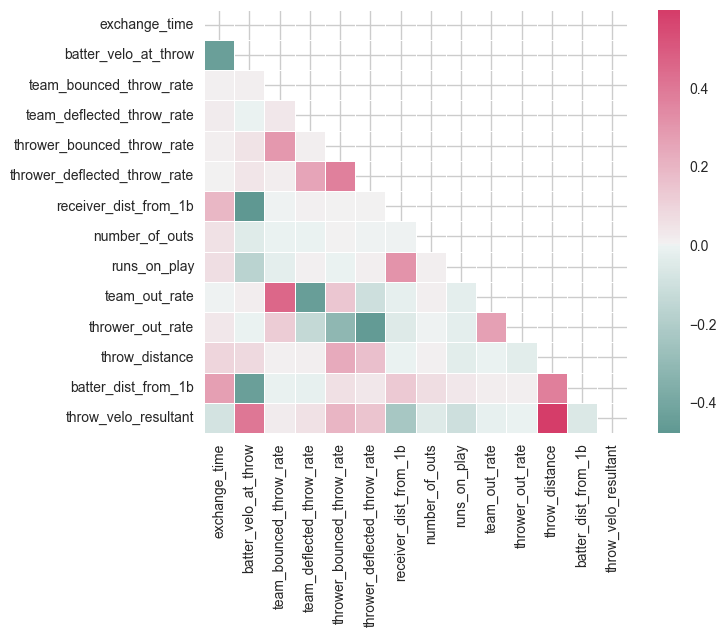

In [23]:
# Separate model features
# Model data numeric features list
modeldata_numeric_features_list = ['exchange_time', 'batter_velo_at_throw', 'team_bounced_throw_rate', 'team_deflected_throw_rate', 'thrower_bounced_throw_rate',
                                  'thrower_deflected_throw_rate', 'receiver_dist_from_1b', 'number_of_outs', 'runs_on_play', 'team_out_rate', 'thrower_out_rate',
                                   'throw_distance', 'batter_dist_from_1b', 'throw_velo_resultant']

# Model data categorical features list
modeldata_categorical_features_list = ['team_id', 'fielder_id', 'fielder_position', 'thrower_id', 'thrower_position', 'receiver_id', 'fielder_thrower_same',
                                      'throw_bounced', 'throw_deflected_by_receiver', 'runner_on_1st', 'runner_on_2nd', 'runner_on_3rd']

# Target feature
model_target_feature = 'batter_out'

# Coorelation matrix
# Calculate correlation coefficients
modeldata_correlation_coefficients_df = modeling_throws_imputed_df[modeldata_numeric_features_list].corr()

# Generate a mask for the upper triangle using an array of the same size as correlation_coefficients_df of True Boolean values
mask = np.triu(np.ones_like(modeldata_correlation_coefficients_df, dtype=bool))

# Generate a custom diverging colormap
cmap = sns.diverging_palette(180, 0, as_cmap=True)

# Make the heatmap
sns.heatmap(modeldata_correlation_coefficients_df, mask=mask, cmap=cmap, center=0, square=True, linewidths=.5)

[Back to List of Notebook Contents](#Infield-Throw-Performance-Project---Modeling)

### Model Development
To efficiently train, experiment, and evaluate various machine learning algorithms, the [PyCaret](https://pycaret.org/) library is used.

In [25]:
# Target feature class proportion breakdown
modeling_throws_imputed_df['batter_out'].value_counts(normalize=True)

batter_out
1.0    0.884245
0.0    0.115755
Name: proportion, dtype: float64

In [26]:
# Setup model and pass in the feature-engineered model data and feature type lists
throws_out_clf = pycaret.setup(data=modeling_throws_imputed_df, target=model_target_feature, numeric_features=modeldata_numeric_features_list,
                             categorical_features=modeldata_categorical_features_list, fold=10, n_jobs=1)

# Add macro F1 model evaluation metric -> good for evaluating models dealing with imbalanced datasets
pycaret.add_metric(id='f1_macro', name='Macro F1', score_func=f1_score, args={'average': 'macro'})

,Description,Value
0,Session id,1870
1,Target,batter_out
2,Target type,Binary
3,Original data shape,"(17347, 27)"
4,Transformed data shape,"(17347, 51)"
5,Transformed train set shape,"(12142, 51)"
6,Transformed test set shape,"(5205, 51)"
7,Numeric features,14
8,Categorical features,12
9,Preprocess,True


Name                                                          Macro F1
Display Name                                                  Macro F1
Score Function       <pycaret.internal.metrics.EncodedDecodedLabels...
Scorer                make_scorer(f1_score, response_method='predict')
Target                                                            pred
Args                                    {'args': {'average': 'macro'}}
Greater is Better                                                 True
Multiclass                                                        True
Custom                                                            True
Name: f1_macro, dtype: object

In [27]:
# Compare learning algorithms based on classifier setup above
# compare_models returns an object of the best learning algorithm
best_model = pycaret.compare_models(errors='raise')

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,Macro F1,TT (Sec)
lightgbm,Light Gradient Boosting Machine,0.9703,0.9840,0.9887,0.9780,0.9833,0.8494,0.8506,0.9833,0.5830
catboost,CatBoost Classifier,0.9702,0.9844,0.9894,0.9772,0.9832,0.8478,0.8496,0.9832,14.0710
xgboost,Extreme Gradient Boosting,0.9691,0.9837,0.9885,0.9768,0.9826,0.8427,0.8443,0.9826,0.8370
gbc,Gradient Boosting Classifier,0.9652,0.9813,0.9889,0.9722,0.9805,0.8190,0.8221,0.9805,5.4690
rf,Random Forest Classifier,0.9597,0.9761,0.9889,0.9664,0.9775,0.7862,0.7915,0.9775,2.9620
ada,Ada Boost Classifier,0.9504,0.9697,0.9819,0.9628,0.9722,0.7403,0.7438,0.9722,1.5660
et,Extra Trees Classifier,0.9423,0.9654,0.9897,0.9475,0.9681,0.6686,0.6874,0.9681,1.6960
dt,Decision Tree Classifier,0.9401,0.8551,0.9657,0.9666,0.9661,0.7085,0.7092,0.9661,0.5320
lr,Logistic Regression,0.9349,0.9377,0.9884,0.9410,0.9641,0.6171,0.6397,0.9641,1.6700
lda,Linear Discriminant Analysis,0.9294,0.9480,0.9888,0.9351,0.9612,0.5732,0.6029,0.9612,0.3390


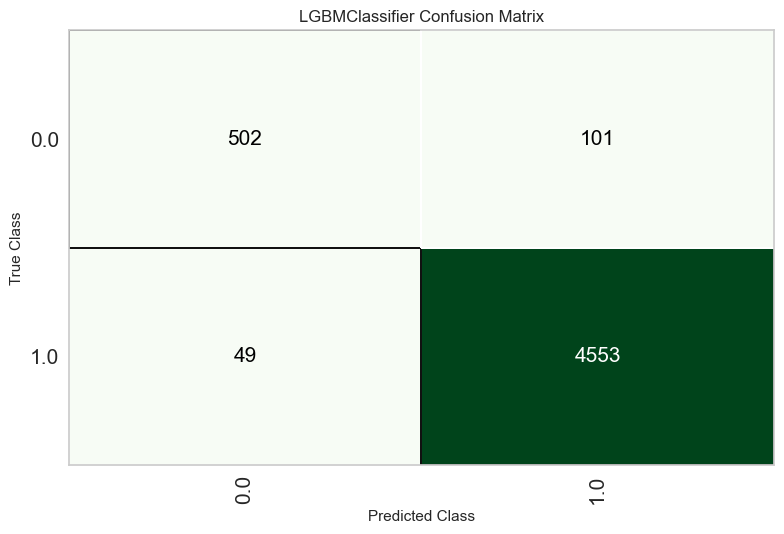

In [28]:
# Delve deeper into the best model with visualizations
pycaret.plot_model(best_model, plot='confusion_matrix')

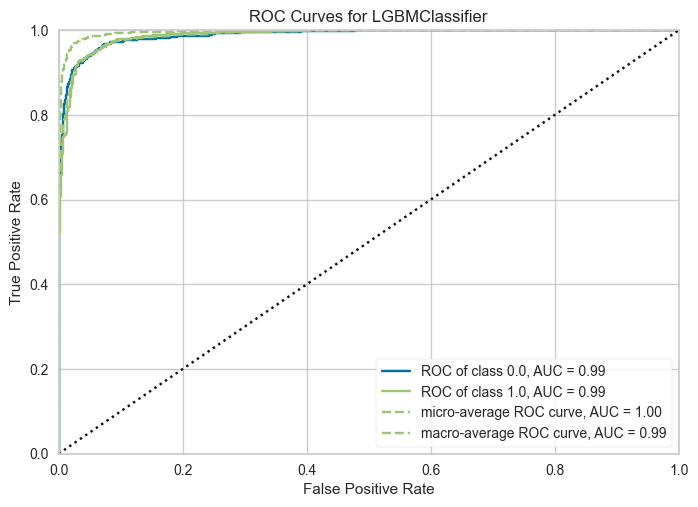

In [29]:
pycaret.plot_model(best_model, plot='auc')

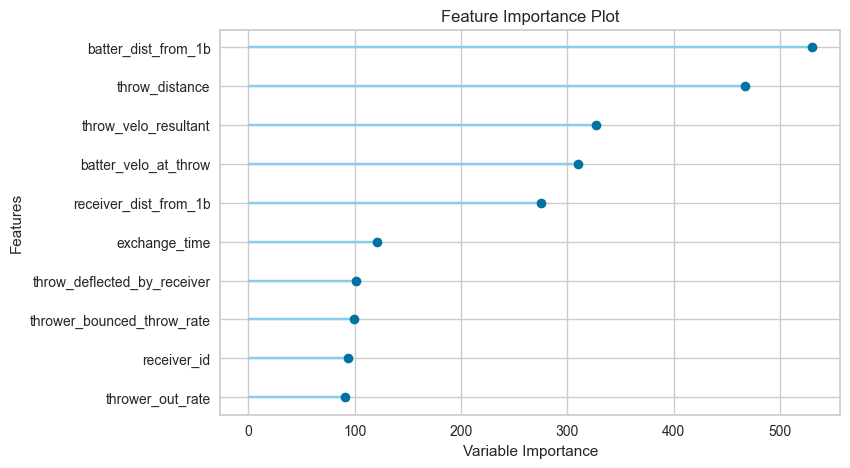

In [30]:
pycaret.plot_model(best_model, plot='feature')

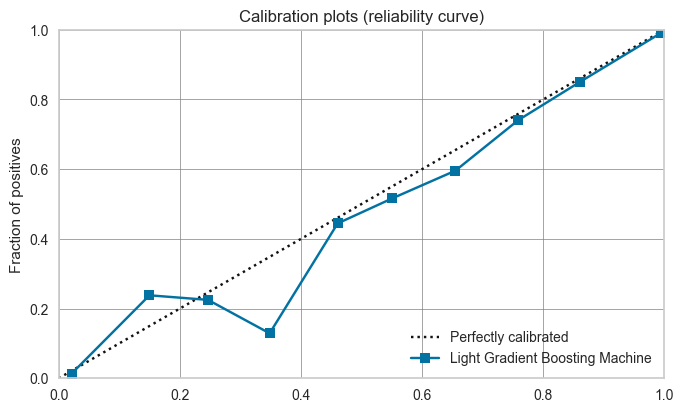

In [31]:
pycaret.plot_model(best_model, plot='calibration')

In [32]:
pycaret.plot_model(best_model, plot='parameter')

,Parameters
boosting_type,gbdt
class_weight,None
colsample_bytree,1.0
importance_type,split
learning_rate,0.1
max_depth,-1
min_child_samples,20
min_child_weight,0.001
min_split_gain,0.0
n_estimators,100


In [33]:
# View test set model prediction performance details
model_prediction_details_df = pycaret.predict_model(best_model, raw_score=True)
model_prediction_details_df

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,Macro F1
0,Light Gradient Boosting Machine,0.9712,0.9880,0.9894,0.9783,0.9838,0.8538,0.8549,0


,team_id,fielder_id,fielder_position,thrower_id,thrower_position,receiver_id,exchange_time,batter_velo_at_throw,fielder_thrower_same,throw_bounced,...,runs_on_play,team_out_rate,thrower_out_rate,throw_distance,batter_dist_from_1b,throw_velo_resultant,batter_out,prediction_label,prediction_score_0,prediction_score_1
11909,6.0,39.0,4.0,39.0,4.0,25.0,0.666,26.407015,1.0,1.0,...,0.0,0.900441,0.876543,113.035027,47.213631,59.929276,0.0,0,0.9977,0.0023
12377,14.0,246.0,6.0,246.0,6.0,534.0,1.266,22.934607,1.0,0.0,...,0.0,0.873794,0.858859,85.547241,49.780392,61.711651,1.0,1,0.0005,0.9995
8876,10.0,46.0,5.0,46.0,5.0,50.0,0.816,24.747023,1.0,1.0,...,0.0,0.889803,0.895604,146.620529,57.977871,63.629681,1.0,1,0.0036,0.9964
3964,15.0,592.0,6.0,592.0,6.0,568.0,1.100,25.782591,1.0,0.0,...,0.0,0.882092,0.870206,101.284195,35.518887,70.066154,1.0,1,0.0044,0.9956
4211,13.0,749.0,6.0,749.0,6.0,408.0,1.067,29.768789,1.0,0.0,...,0.0,0.900763,0.902128,114.111107,37.173798,81.300354,1.0,1,0.0188,0.9812
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13148,14.0,662.0,5.0,85.0,4.0,534.0,0.466,28.307425,0.0,0.0,...,0.0,0.873794,0.866667,86.128098,27.233263,68.119751,0.0,0,0.9795,0.0205
12777,14.0,246.0,6.0,246.0,6.0,534.0,1.333,23.098526,1.0,0.0,...,0.0,0.873794,0.858859,116.143837,48.887741,71.082054,1.0,1,0.0011,0.9989
8304,1.0,314.0,4.0,314.0,4.0,514.0,1.000,27.143492,1.0,0.0,...,0.0,0.881197,0.874510,101.629326,42.471210,74.531548,1.0,1,0.0018,0.9982
12008,13.0,688.0,6.0,688.0,6.0,310.0,1.100,28.726944,1.0,0.0,...,0.0,0.900763,0.902357,100.273048,37.255917,85.288330,1.0,1,0.0089,0.9911


[Back to List of Notebook Contents](#Infield-Throw-Performance-Project---Modeling)

### Linking Model Prediction to Throw Performance

The model outputs a target class prediction and the prediction score, which represents the prediction probabilities for each of the target feature classes. For this model, the probabilities of both classes out (`1`) or safe (`0`) of the `batter_out` target feature can be leveraged to compute an evaluation metric that quantifies an infielder's value on throws to first. 

In [35]:
# Retrieve a portion of the test set and its prediction results
model_prediction_details_df[['batter_out', 'prediction_score_0', 'prediction_score_1']].head(5)

,batter_out,prediction_score_0,prediction_score_1
11909,0.0,0.9977,0.0023
12377,1.0,0.0005,0.9995
8876,1.0,0.0036,0.9964
3964,1.0,0.0044,0.9956
4211,1.0,0.0188,0.9812


In first row in the table above, the batter was not thrown out, but the out probability was almost 0. Had the infielder recorded the out, they would have been credited with a 0.9977 number of outs recorded above expectation per throw:
- 1 actual out recorded by their throw to first
- 0.23% probability
- 1 throw made
  
`(1 - 0.0023) / 1 = 0.9977 outs recorded above expectation per throw`

But since they did not record an out, their outs recorded above expectation per throw is -0.0023 meaning the infielder is performing below expectation.

`(0 - 0.0023) / 1 = -0.0023 outs recorded above expectation per throw`

The second throw was an out and had a high probability of being an out. For this throw, the number of outs recorded above expectation per throw is 0.0005.

If the five throws above came from the same infielder, the infielder would have a 0.005 outs recorded above expectation per throw, indicating that the infielder is performing almost as expected.

[Back to List of Notebook Contents](#Infield-Throw-Performance-Project---Modeling)

### Future Directions
Although the developed model is very performant, it would be interesting to see how much more strongly, if at all, the model would perform if the model was trained on more data. 

Even though the model performance is good as is, I would haved like to try tuning it if I had more time to wring out more performance.

Features that describe how an infielder gets to the ball and the movement of the ball prior to the making a throw to first could add value to a model when predicting the outcome of a throw. These features could be:
-	Reaction time of the fielder, thrower, and receiver defined as the time elapsed between when the ball is hit and when the player velocity exceeds a threshold
-	Distance traveled by the thrower prior to throw
-	Time between when the ball is hit and throw
-	Receiver velocity
-	Exit velocity of ball

From a macro baseball perspective, the throwing error rate of players could be a useful feature and add information about the defensive ability of the thrower to the model.

[Back to List of Notebook Contents](#Infield-Throw-Performance-Project---Modeling)